In [1]:
%pip install pandas geopandas


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import geopandas as gpd
df = pd.read_csv("data/hydropower_plant_location_database.csv", encoding="cp1252")
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.Longitude, df.Latitude), crs="EPSG:4326")
nc = gdf[gdf.State == "NC"]

In [3]:
df.columns.tolist()

['EHA_PtID',
 'PtName',
 'County',
 'State',
 'Latitude',
 'Longitude',
 'Pt_Own',
 'OwType',
 'Dam_Own',
 'Type',
 'EIA_PtID',
 'FC_Dock',
 'FcIssue',
 'FcExpire',
 'Mode',
 'Pm_Type',
 'Number_of_Units',
 'HY_MW',
 'HY_MWh',
 'HY_Pf',
 'HY_OpYear',
 'PSH_MW',
 'PSH_MWh',
 'PSH_Pf',
 'PSH_OpYear',
 'Water',
 'HUC12_All',
 'FIPS_Census',
 'NERC',
 'BACode',
 'Sector',
 'Trans']

In [4]:
df.head()

,EHA_PtID,PtName,County,State,Latitude,Longitude,Pt_Own,OwType,Dam_Own,Type,...,PSH_MWh,PSH_Pf,PSH_OpYear,Water,HUC12_All,FIPS_Census,NERC,BACode,Sector,Trans
0,hc1586_p01,Rocky River,Litchfield,CT,41.582649,-73.434820,FirstLight Power Resources Services LLC,Wholesale Power Marketer,FirstLight Power Resources Services LLC,PSH,...,13908.04,5.121535,1928.0,Rocky River,1.100005e+10,9005.0,NPCC,ISNE,IPP Non-CHP,Connecticut Light & Power Co
1,hc0015_p01,Flatiron,Larimer,CO,40.364996,-105.236032,U S Bureau of Reclamation,Reclamation,Reclamation Great Plains Region (GP),HY/PSH,...,25486.08,34.227881,1954.0,Colorado River,1.019001e+11,8069.0,WECC,WACM,Electric Utility,WAPA-- Western Area Power Administration
2,hc0038_p01,ONeill,Merced,CA,37.098671,-121.047718,U S Bureau of Reclamation,Reclamation,U S Bureau of Reclamation,PSH,...,36101.08,16.353682,1967.0,O'Neill Forebay - San Luis Cre,1.804000e+11,6047.0,WECC,CISO,Electric Utility,WAPA-- Western Area Power Administration
3,hc0112_p01,Waddell,Maricopa,AZ,33.846400,-112.266300,Central Arizona Water Conservation Dist,Publicly Owned Utility,U S Bureau of Reclamation,PSH,...,40888.58,11.669115,1993.0,Agua Fria River,1.507010e+11,4013.0,WECC,WALC,Electric Utility,Arizona Public Service Co
4,hc1233_p01,Thermalito,Butte,CA,39.525200,-121.601200,California Dept. of Water Resources,State,California Department of Water Resources,HY/PSH,...,43363.55,6.000214,1968.0,Feather River - Os,1.802016e+11,6007.0,WECC,CISO,Electric Utility,Pacific Gas & Electric Co


Geometry comes from code above turning lat + long into it.

In [5]:
cols = ["EHA_PtID", "PtName", "County", "State", "Type", "HY_MW", "HY_OpYear", "geometry"]
nc_clean = nc[cols].rename(columns={
    "EHA_PtID": "facility_id", "PtName": "name", "County": "county", "State": "state",
    "Type": "energy_type", "HY_MW": "capacity_mw", "HY_OpYear": "year"})
nc_clean["energy_type"] = "hydropower"
print(len(nc_clean))
nc_clean.head()

55


,facility_id,name,county,state,energy_type,capacity_mw,year,geometry
6,hc0813_p01,Hiwassee Dam,Cherokee,NC,hydropower,70.600,1940.0,POINT (-84.178 35.152)
99,hc7057_p01,Little River,Montgomery,NC,hydropower,0.575,1997.0,POINT (-79.8938 35.2842)
105,hc7066_p01,Mcadenville,Gaston,NC,hydropower,1.040,1984.0,POINT (-81.0766 35.2617)
123,hc7097_p01,Eury,Montgomery,NC,hydropower,0.800,1983.0,POINT (-79.909 35.2538)
155,hc7182_p01,Hardins,Gaston,NC,hydropower,0.720,NaN,POINT (-81.1853 35.3823)


In [6]:
len(df)

2257

In [7]:
nc_clean.to_file("data/nc_hydro_clean.geojson")

In [8]:
len(nc_clean)

55

In [9]:
def clean_hydro(path, state=None, include_psh=True):
    df = pd.read_csv(path, encoding="cp1252")
    # trim stray spaces in text columns
    for c in df.select_dtypes(include=["object", "string"]).columns:
        df[c] = df[c].str.strip()
    # capacity and year: use hydro values, fall back to pumped storage for PSH-only plants
    df["capacity_mw"] = df["HY_MW"].fillna(df["PSH_MW"])
    df["year"] = df["HY_OpYear"].fillna(df["PSH_OpYear"]).astype("Int64")
    if not include_psh:
        df = df[df["Type"] != "PSH"]
    if state:
        df = df[df["State"] == state]
    df = df.rename(columns={"EHA_PtID": "facility_id", "PtName": "name",
                            "County": "county", "State": "state", "Type": "hydro_type"})
    df["energy_type"] = "hydropower"
    keep = ["facility_id", "name", "energy_type", "hydro_type", "capacity_mw", "year",
            "state", "county", "Latitude", "Longitude"]
    df = df[keep]
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.Longitude, df.Latitude),
                            crs="EPSG:4326").drop(columns=["Latitude", "Longitude"])

In [10]:
hydro_csv = hydro.assign(longitude=hydro.geometry.x, latitude=hydro.geometry.y).drop(columns="geometry")
hydro_csv.to_csv("data/hydro_clean.csv", index=False)

NameError: name 'hydro' is not defined

In [ ]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.4 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.5 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.1 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import matplotlib.pyplot as plt

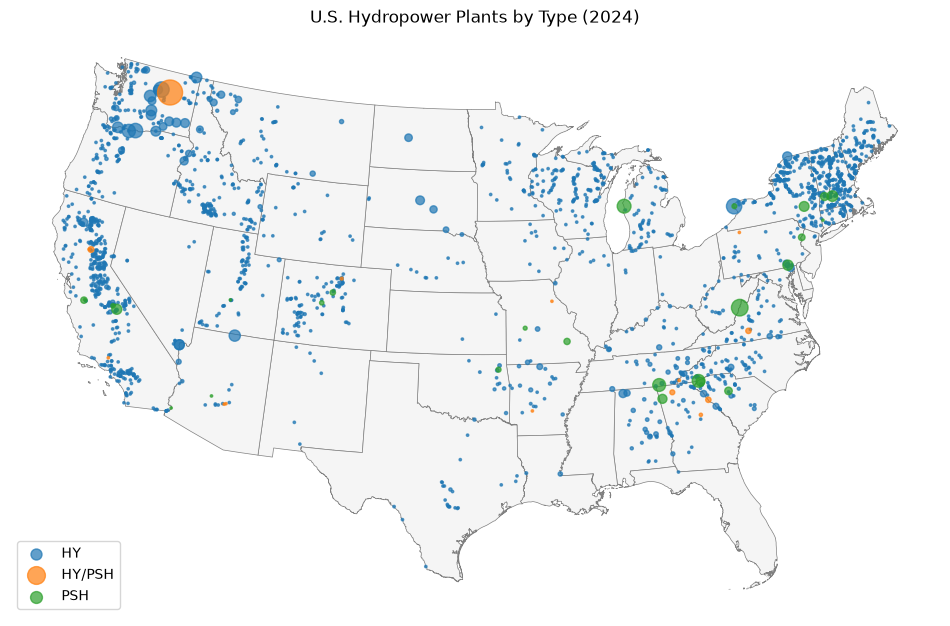

In [ ]:
states = gpd.read_file("data/cb_2024_us_state_500k.zip")

# lower 48 only, reprojected so the US isn't stretched
skip = ["AK", "HI", "PR", "GU", "VI", "MP", "AS"]
states48 = states[~states.STUSPS.isin(skip)].to_crs("EPSG:5070")
hydro48 = hydro[~hydro.state.isin(skip)].to_crs("EPSG:5070")

fig, ax = plt.subplots(figsize=(12, 8))
states48.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.5)
hydro48.plot(ax=ax, column="hydro_type", categorical=True, legend=True,
             markersize=(hydro48.capacity_mw / 20).clip(lower=3), alpha=0.7)
ax.set_title("U.S. Hydropower Plants by Type (2024)")
ax.set_axis_off()
plt.show()